# Day 4 — Reinforcement Learning (Educational Focus)

Welcome to Day 3 of the **UR5 AI Workshop**. Today we focus on the **principles of Reinforcement Learning (RL)** using simple, interpretable environments (grid world) before mapping concepts to robotics.

### 🎯 Learning Objectives
- Understand Markov Decision Processes (MDP), states, actions, rewards, and policies.
- Implement and train a Q-learning agent on a discrete GridWorld.
- Compare Q-learning with dynamic programming (Value Iteration).
- Map discrete RL outputs to simple robot-like actions for intuition towards UR5 control.


## 1. Quick theory: MDP and Q-learning

- MDP: (S, A, P, R, gamma). We will use deterministic transitions.
- Q-learning update: Q(s,a) <- Q(s,a) + alpha [r + gamma max_a' Q(s',a') - Q(s,a)]
- Epsilon-greedy exploration for action selection.


## 🧩 Exercise 1 — Implement a GridWorld Environment

In [1]:
# Student Task: Implement a simple GridWorld class with:
# - state as (row, col)
# - actions: 0=up,1=right,2=down,3=left
# - step(action) -> next_state, reward, done

class GridWorld:
    def __init__(self, n_rows=5, n_cols=5, start=(0,0), goal=(4,4), obstacles=[(1,1), (1,2), (3,2), (3,3)]):
        self.n_rows = n_rows
        self.n_cols = n_cols
        self.start = start
        self.goal = goal
        self.obstacles = set(obstacles) if obstacles else set()
        self.reset()
    def reset(self):
        self.state = self.start
        return self.state
    def in_bounds(self, s):
        r,c = s
        return 0 <= r < self.n_rows and 0 <= c < self.n_cols
    def step(self, action):
        dr, dc = [(-1, 0), (0, 1), (1, 0), (0, -1)][action]
        new = (self.state[0] + dr, self.state[1] + dc)
        if not self.in_bounds(new) or new in self.obstacles:
            return self.state, -5, False      # bumped into a wall/obstacle: stay, penalty
        self.state = new
        if new == self.goal:
            return new, 10, True              # reached the goal
        return new, -1, False                 # every step costs 1 -> shortest path is best

env = GridWorld()
print('Initial state:', env.reset())
print('step right:', env.step(1))
print('step down (obstacle):', env.step(2))


Initial state: (0, 0)
step right: ((0, 1), -1, False)
step down (obstacle): ((0, 1), -5, False)


## 🧩 Exercise 2 — Implement Q-learning Agent

Trained Q sample for start state: [-3.2, 2.53, -3.84, -2.84]


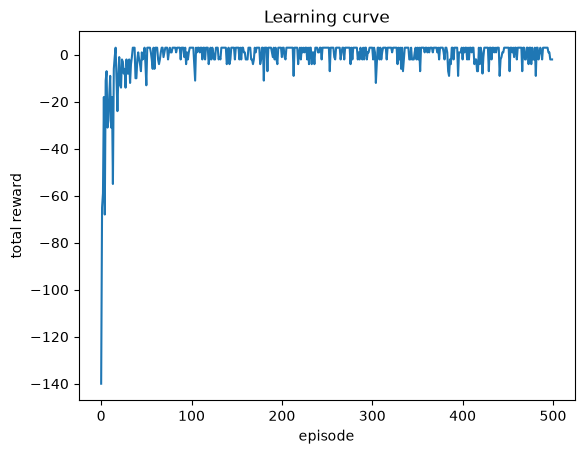

In [2]:
# Student Task: Implement Q-learning training loop for GridWorld
import random, math
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

def q_learning(env, episodes=500, alpha=0.1, gamma=0.99, epsilon=0.1):
    Q = defaultdict(lambda: [0.0,0.0,0.0,0.0])
    rewards = []
    for ep in range(episodes):
        state = env.reset()
        done = False
        total = 0
        for _ in range(200):  # max steps per episode
            if random.random() < epsilon:
                action = random.randrange(4)                           # explore
            else:
                action = max(range(4), key=lambda a: Q[state][a])     # exploit
            next_state, reward, done = env.step(action)
            target = reward + (0 if done else gamma * max(Q[next_state]))
            Q[state][action] += alpha * (target - Q[state][action])
            state = next_state
            total += reward
            if done:
                break
        rewards.append(total)
    return Q, rewards

random.seed(0)
env = GridWorld()
Q, rewards = q_learning(env, episodes=500)
print('Trained Q sample for start state:', [round(q, 2) for q in Q[env.start]])

plt.plot(rewards)
plt.xlabel('episode'); plt.ylabel('total reward'); plt.title('Learning curve')
plt.show()


## 🧩 Exercise 3 — Policy Evaluation & Visualization

Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]


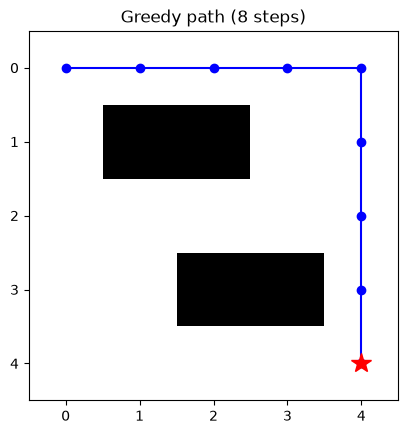

In [3]:
# Student Task: Derive greedy policy from Q and simulate one episode to show path
def greedy_policy(Q, state):
    qvals = Q.get(state, [0,0,0,0])
    return max(range(4), key=lambda a: qvals[a])

env = GridWorld()
state = env.reset()
path = [state]
for _ in range(50):
    a = greedy_policy(Q, state)
    state, r, done = env.step(a)
    path.append(state)
    if done:
        break
print('Path:', path)

grid = np.zeros((env.n_rows, env.n_cols))
for o in env.obstacles:
    grid[o] = 1
plt.imshow(grid, cmap='Greys')
plt.plot([p[1] for p in path], [p[0] for p in path], 'b-o')
plt.plot(env.goal[1], env.goal[0], 'r*', markersize=15)
plt.title(f'Greedy path ({len(path) - 1} steps)'); plt.show()


## 🧩 Exercise 4 — Value Iteration (Dynamic Programming)

Sample V at start: 2.5271882697689003
Q-learning best value at start: 2.53


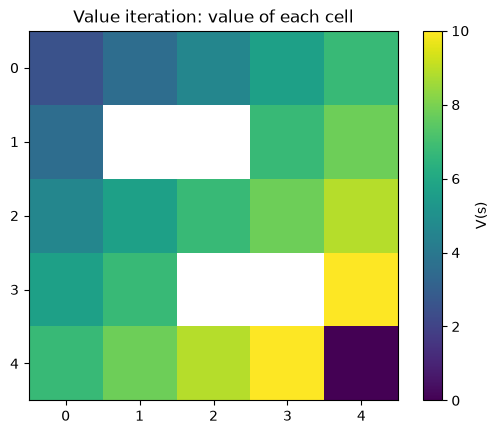

In [4]:
# Student Task: Implement value iteration for the GridWorld (deterministic transitions)
def value_iteration(env, gamma=0.99, theta=1e-4):
    states = [(r, c) for r in range(env.n_rows) for c in range(env.n_cols) if (r, c) not in env.obstacles]
    V = {s: 0.0 for s in states}
    while True:
        delta = 0
        for s in states:
            if s == env.goal:
                continue  # terminal state
            values = []
            for a in range(4):
                env.state = s                      # "what if I take action a from s?"
                s2, r, done = env.step(a)
                values.append(r + (0 if done else gamma * V[s2]))
            best = max(values)
            delta = max(delta, abs(best - V[s]))
            V[s] = best
        if delta < theta:
            return V

env = GridWorld()
V = value_iteration(env)
print('Sample V at start:', V.get(env.start))
print('Q-learning best value at start:', round(max(Q[env.start]), 2))  # should be close

grid = np.full((env.n_rows, env.n_cols), np.nan)
for s, v in V.items():
    grid[s] = v
plt.imshow(grid, cmap='viridis'); plt.colorbar(label='V(s)')
plt.title('Value iteration: value of each cell'); plt.show()


## 🧩 Exercise 5 — Mapping Discrete Actions to Robot-like Commands

Map the 4-grid actions to small TCP translations (conceptual).

In [5]:
# Student Task:
# grid rows -> robot X, grid columns -> robot Y (same as Day 3)
def grid_action_to_tcp_delta(action, step_size=0.05):
    return {0: [-step_size, 0, 0],    # up    -> -X
            1: [0, -step_size, 0],    # right -> -Y
            2: [step_size, 0, 0],     # down  -> +X
            3: [0, step_size, 0]}[action]  # left -> +Y

for a, name in enumerate(['up', 'right', 'down', 'left']):
    print('Mapping example:', name, '->', grid_action_to_tcp_delta(a))


Mapping example: up -> [-0.05, 0, 0]
Mapping example: right -> [0, -0.05, 0]
Mapping example: down -> [0.05, 0, 0]
Mapping example: left -> [0, 0.05, 0]


## 🎓 Final Challenge — From GridWorld to URSim
Use your trained Q-table to command small TCP deltas in URSim. Test in simulation with small step sizes and exercise caution.

In [ ]:
# Disconnect the other notebooks from the robot first.
from rtde_control import RTDEControlInterface
from rtde_receive import RTDEReceiveInterface

rtde_c = RTDEControlInterface('127.0.0.1')
rtde_r = RTDEReceiveInterface('127.0.0.1')

down = [0, math.pi, 0]
rtde_c.moveJ([-0.301, -1.528, 2.179, -2.221, -1.571, -1.872], 0.5, 0.5)  # start pose above the table
pose = [-0.55, 0.10, 0.20] + down     # grid cell (0, 0) on the table 
rtde_c.moveL(pose, 0.25, 0.5)

env = GridWorld()
state = env.reset()
for _ in range(20):
    a = greedy_policy(Q, state)
    old = state
    state, r, done = env.step(a)
    if state == old:
        continue                       # bumped into something: don't move the robot
    delta = grid_action_to_tcp_delta(a)
    pose = [pose[i] + delta[i] for i in range(3)] + down
    rtde_c.moveL(pose, 0.1, 0.3)       # small, slow steps
    print('action', a, '-> cell', state, '-> tool', [round(v, 3) for v in rtde_r.getActualTCPPose()[:3]])
    if done:
        print('Goal reached!')
        break

rtde_c.stopScript()
rtde_c.disconnect()
rtde_r.disconnect()


connect: Connection refused


RuntimeError: Error: Could not connect to: 127.0.0.1 at 30004, verify the IP